In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import json
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torch import nn 
import torch.nn.functional as F
from torchvision.transforms import v2
import random
import numpy as np
import math
import time

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

seed_everything()

## 1. Data

In [3]:
class LeafDataset():
    def __init__(self, df, images, transform, has_labels=True):
        images_dir = Path(images)
        self.paths = [images_dir / name for name in df["image_id"]]
        self.labels = (
            df["label"].to_numpy(dtype="int64", copy=True)
            if "label" in df.columns
            else None
        )    
        self.transform = transform

    def __len__(self):
        return len(self.paths)
        
    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
            if self.transform is not None:
                image = self.transform(image)

        sample = {
            "image": image,
            "image_id": path.name,
        }
        
        if self.labels is not None:
            sample["label"] = int(self.labels[index])
            
        return sample

In [4]:
ROOT = Path("/kaggle/input/competitions/cassava-leaf-disease-classification")
with open(ROOT / "label_num_to_disease_map.json", encoding="utf-8") as file:
    label_names = json.load(file)

df = pd.read_csv(ROOT / "train.csv")
train_df, val_test_df = train_test_split(
    df, 
    test_size=0.2,
    stratify=df["label"],
    random_state=SEED
)
val_df, test_df = train_test_split(
    val_test_df, 
    test_size=0.5,
    stratify=val_test_df["label"],
    random_state=SEED
)

In [5]:
IMAGE_SIZE = 224

transform = v2.Compose([
    v2.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

train_dataset = LeafDataset(train_df, ROOT / "train_images", transform)
val_dataset = LeafDataset(val_df, ROOT / "train_images", transform)
test_dataset = LeafDataset(test_df, ROOT / "train_images", transform)

In [6]:
def show_samples(dataset, label_names, n=6, cols=2):
    indices = random.sample(range(len(dataset)), n)
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(cols * 4, rows * 4),
        squeeze=False,
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, index in zip(axes.flat, indices):
        sample = dataset[index]
        image = sample["image"]
        
        if isinstance(image, torch.Tensor):
            image = image.detach().cpu().permute(1, 2, 0)

        ax.imshow(image)
        ax.set_title(
            label_names[str(sample["label"])],
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

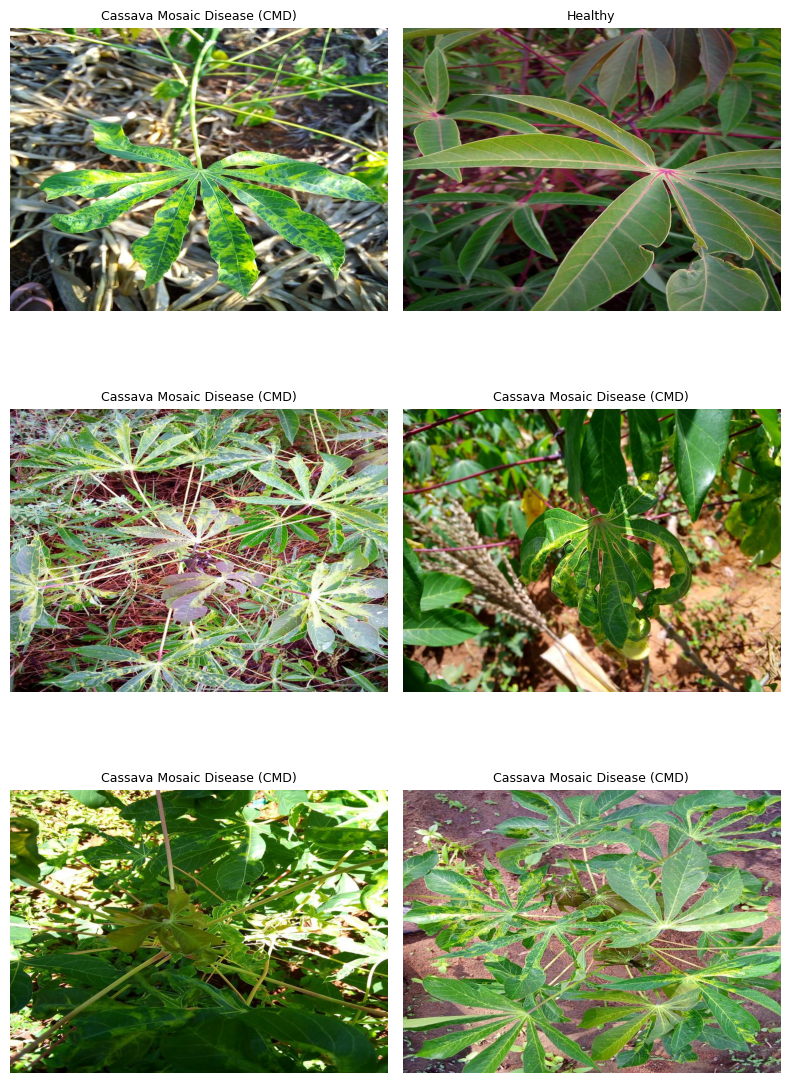

In [7]:
vis_dataset = LeafDataset(train_df, ROOT / "train_images", None)
show_samples(vis_dataset, label_names, n=6, cols=2)

In [8]:
BATCH_SIZE = 32
NUM_WORKERS = 2
use_cuda = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=use_cuda
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=use_cuda
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=use_cuda
)

# 2. Models

## 2.1 ViT

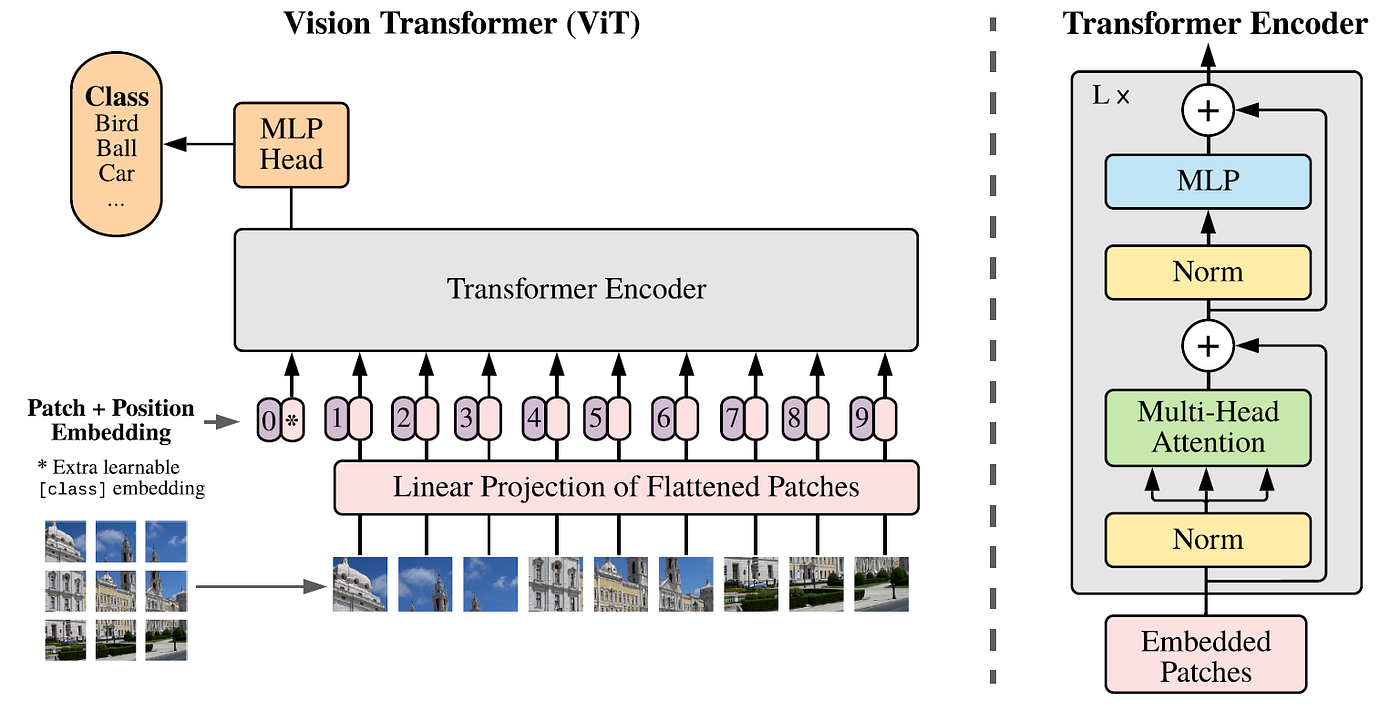
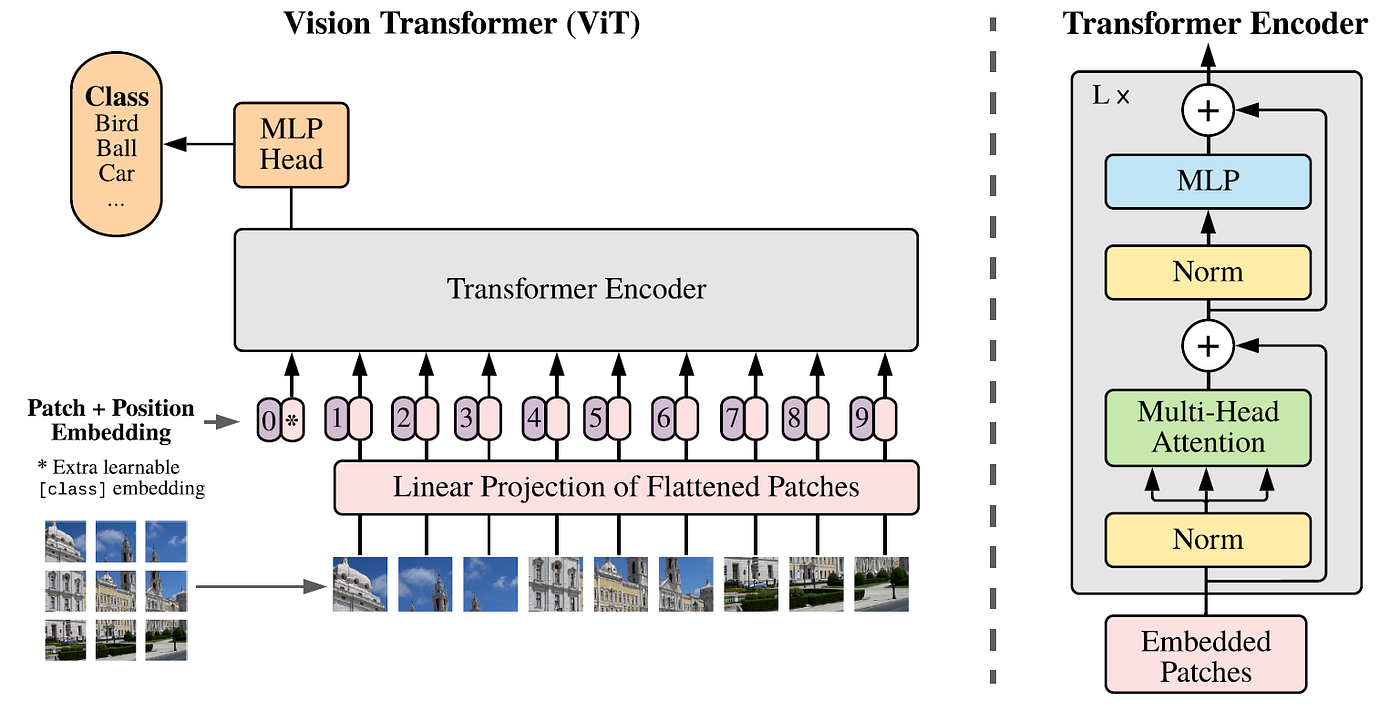

### 2.1.1 Patches Embedings
Getting embedings from images

In [9]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, embed_dim):
        super().__init__()
        assert image_size % patch_size == 0
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        self.proj = nn.Conv2d(
            in_channels,
            embed_dim,
            patch_size,
            patch_size
        )

    def forward(self, images):
        """
        images: (B, 3, H, W)
        emb: (B, N, D)
        """
        emb = self.proj(images).flatten(2).transpose(1, 2)
        return emb

### 2.1.2 Multi-Head self-attention
Counting image self-attention in *n* heads, then concatenating results from them and sending through Linear layer

In [10]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.attn_dropout = nn.Dropout(dropout)

        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.proj_dropout = nn.Dropout(dropout)

    def forward(self, x):
        """
        x: (B, T, D)
        output, attn_w: (B, T, D), (B, num_heads, T, T)
        """
        B, T, D = x.shape
        qkv = self.qkv(x).reshape(B, T, self.num_heads, self.head_dim, 3).transpose(1, 2)
        q, k, v = qkv.unbind(dim=-1)

        attn_w = torch.softmax(q @ k.transpose(-1, -2) / math.sqrt(self.head_dim), dim=-1)
        head_output = self.attn_dropout(attn_w) @ v

        output = head_output.transpose(1, 2).reshape(B, T, D)
        output = self.proj_dropout(self.out_proj(output))
        return (output, attn_w)

### 2.1.3 MLP and ViT block


In [11]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )
        
    def forward(self, x):
        return self.net(x)

In [12]:
class ViTBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = FeedForward(embed_dim, dropout)

    def forward(self, x):
        """
        x: (B, T, D)
        x, attn_w: (B, T, D), (B, num_heads, T, T)
        """
        attn_output, attn_w = self.attn(self.norm1(x))
        x = x + attn_output
        x = x + self.mlp(self.norm2(x))

        return (x, attn_w)

### 2.1.4 ТinyVit
Gathering all written blocks into one pipeline

In [13]:
class TinyViT(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, 
                 num_classes, embed_dim, num_heads, depth, dropout):
        super().__init__()
        self.patch_size = patch_size
        self.image_size = image_size
        self.num_patches = (image_size // patch_size) ** 2
        self.patch_embed = PatchEmbedding(image_size, patch_size, in_channels, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))
        self.blocks = nn.ModuleList([
            ViTBlock(embed_dim, num_heads, dropout)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self.apply(self._init_weights)
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, images, **kwargs):
        return self.forward_tokens(self.patch_embed(images), **kwargs)

    def forward_tokens(self, patches, use_positions=True, return_attention=False):
        B, N, D = patches.shape
        assert N == self.num_patches

        x = torch.cat([self.cls_token.expand(B, 1, D), patches], dim=1)
        if use_positions:
            x = x + self.pos_embed

        attentions = []
        for block in self.blocks:
            x, attention = block(x)
            if return_attention:
                attentions.append(attention)

        cls = self.norm(x)[:, 0, :]
        logits = self.head(cls)
        return (logits, attentions) if return_attention else logits

In [14]:
IN_CHANNELS = 3
NUM_CLASSES = len(label_names)
PATCH_SIZE = 16
EMBED_DIM = 128
NUM_HEADS = 4
DEPTH = 3
DROPOUT = 0.1
EPOCHS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
assert IMAGE_SIZE % PATCH_SIZE == 0
assert EMBED_DIM % NUM_HEADS == 0

def model_config(patch_size):
    return dict(image_size=IMAGE_SIZE, patch_size=patch_size, in_channels=IN_CHANNELS, 
                num_classes=NUM_CLASSES, embed_dim=EMBED_DIM, num_heads=NUM_HEADS, 
                depth=DEPTH, dropout=DROPOUT)

In [15]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for batch in loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=-1) == y).sum().item()
        total += len(y)
    return {"loss": total_loss / total, "accuracy": correct / total}

def fit_model(model, train_loader, val_loader):
    seed_everything(SEED)

    # Настраиваем оптимизатор
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    # Оцениваем модель до обучения
    baseline = evaluate(model, val_loader)
    print(f"P={model.patch_size} | параметров={sum(p.numel() for p in model.parameters()):,} | "
          f"валидация до обучения: потери={baseline['loss']:.3f}, доля верных ответов={baseline['accuracy']:.1%}")

    # Инициализируем логгеры метрик.
    history = []
    best_loss, best_state, best_epoch = float("inf"), None, None
    train_seconds = 0.0
    synchronize()
    wall_start = time.perf_counter()

    # Обучение.
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        synchronize()
        start = time.perf_counter()

        for batch in train_loader:
            x, y = batch["image"].to(device), batch["label"].to(device)

            logits = model(x)

            loss = F.cross_entropy(logits, y)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)

            # логгируем метрики.
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(-1) == y).sum().item()
            total += len(y)

        # Вывод метрик и оценка модели после эпохи обучения.
        synchronize()
        epoch_seconds = time.perf_counter() - start
        train_seconds += epoch_seconds
        validation = evaluate(model, val_loader)
        history.append(dict(epoch=epoch, train_loss=total_loss / total, train_acc=correct / total,
                            val_loss=validation["loss"], val_acc=validation["accuracy"]))

        if validation["loss"] < best_loss:
            best_loss, best_epoch = validation["loss"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        scheduler.step()
        print(f"эпоха {epoch:2d}/{EPOCHS} | потери на обучении {total_loss/total:.3f}, доля верных {correct/total:.1%} | "
              f"потери на валидации {validation['loss']:.3f}, доля верных {validation['accuracy']:.1%} | обучение {epoch_seconds:.1f}с")

    synchronize()
    wall_seconds = time.perf_counter() - wall_start
    model.load_state_dict(best_state)
    model.eval()
    Path("checkpoints").mkdir(exist_ok=True)
    torch.save({"state_dict": best_state, "config": model_config(model.patch_size),
                "seed": SEED, "best_epoch": best_epoch, "model_class": type(model).__name__},
               f"checkpoints/{type(model).__name__}_p{model.patch_size}.pt")
    best = history[best_epoch - 1]
    print(f"Лучшая эпоха: {best_epoch}; обучение {train_seconds:.1f}с; полное время {wall_seconds:.1f}с")
    return dict(model=model, history=history, baseline=baseline, best_epoch=best_epoch,
                val_loss=best["val_loss"], val_acc=best["val_acc"], train_seconds=train_seconds,
                wall_seconds=wall_seconds, parameters=sum(p.numel() for p in model.parameters()),
                updates=EPOCHS * len(train_loader))

def plot_history(result, title):
    '''
    Вспомогательная функция построения графиков обучения.
    '''
    h = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, train_key, val_key, ylabel in [
        (axes[0], "train_loss", "val_loss", 'Кросс-энтропия'),
        (axes[1], "train_acc", "val_acc", 'Доля верных ответов')
    ]:
        ax.plot([r["epoch"] for r in h], [r[train_key] for r in h], label='обучение (в течение эпохи)')
        ax.plot([r["epoch"] for r in h], [r[val_key] for r in h], label='валидация')
        ax.axvline(result["best_epoch"], ls="--", color="gray", alpha=0.6, label='выбранная эпоха')
        ax.set(xlabel='Эпоха', ylabel=ylabel, title=f"{title}: {ylabel}")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

P=16 | параметров=719,493 | валидация до обучения: потери=1.720, доля верных ответов=5.0%
эпоха  1/8 | потери на обучении 1.179, доля верных 61.4% | потери на валидации 1.130, доля верных 61.7% | обучение 147.0с
эпоха  2/8 | потери на обучении 1.104, доля верных 62.7% | потери на валидации 1.088, доля верных 62.5% | обучение 83.4с
эпоха  3/8 | потери на обучении 1.081, доля верных 62.8% | потери на валидации 1.064, доля верных 62.9% | обучение 83.9с
эпоха  4/8 | потери на обучении 1.062, доля верных 63.1% | потери на валидации 1.058, доля верных 63.3% | обучение 82.4с
эпоха  5/8 | потери на обучении 1.037, доля верных 63.3% | потери на валидации 1.016, доля верных 63.8% | обучение 81.0с
эпоха  6/8 | потери на обучении 1.013, доля верных 63.6% | потери на валидации 1.003, доля верных 63.9% | обучение 80.2с
эпоха  7/8 | потери на обучении 0.991, доля верных 64.0% | потери на валидации 1.000, доля верных 63.9% | обучение 80.1с
эпоха  8/8 | потери на обучении 0.979, доля верных 64.3% | пот

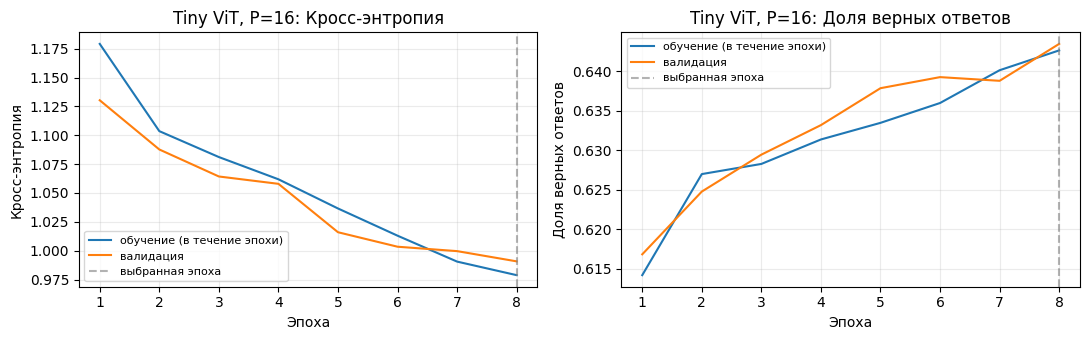

In [16]:
seed_everything(SEED)

model = TinyViT(**model_config(PATCH_SIZE)).to(device)
main_result = fit_model(model, train_loader, val_loader)
model = main_result["model"]
plot_history(main_result, f"Tiny ViT, P={PATCH_SIZE}")

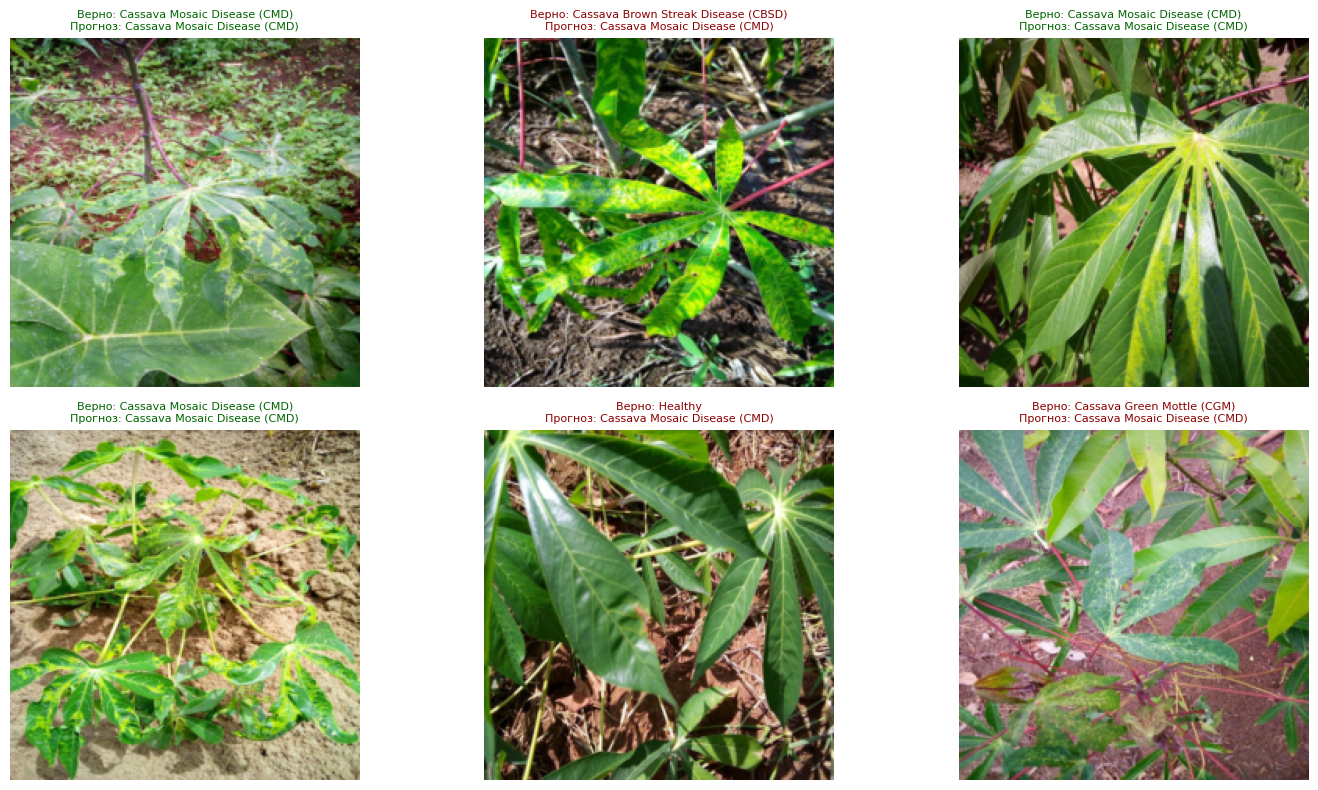

In [17]:
# Фиксируем валидационную подвыборку для двух следующих исследований.
batch = next(iter(val_loader))
exp_x = batch["image"][:6].to(device)
exp_y = batch["label"][:6].to(device)
model.eval()
with torch.no_grad():
    exp_logits = model(exp_x)
    exp_predictions = exp_logits.argmax(dim=-1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, ax in enumerate(axes.ravel()):
    true_id, pred_id = exp_y[i].item(), exp_predictions[i].item()
    ax.imshow(exp_x[i].detach().cpu().permute(1, 2, 0))
    ax.set_title(
        f"Верно: {label_names[str(true_id)]}\n"
        f"Прогноз: {label_names[str(pred_id)]}",
        fontsize=8,
        color="darkgreen" if true_id == pred_id else "darkred",
    )
    ax.axis("off")
plt.tight_layout(); plt.show()

Test loss: 1.0005 | Test accuracy: 63.50%


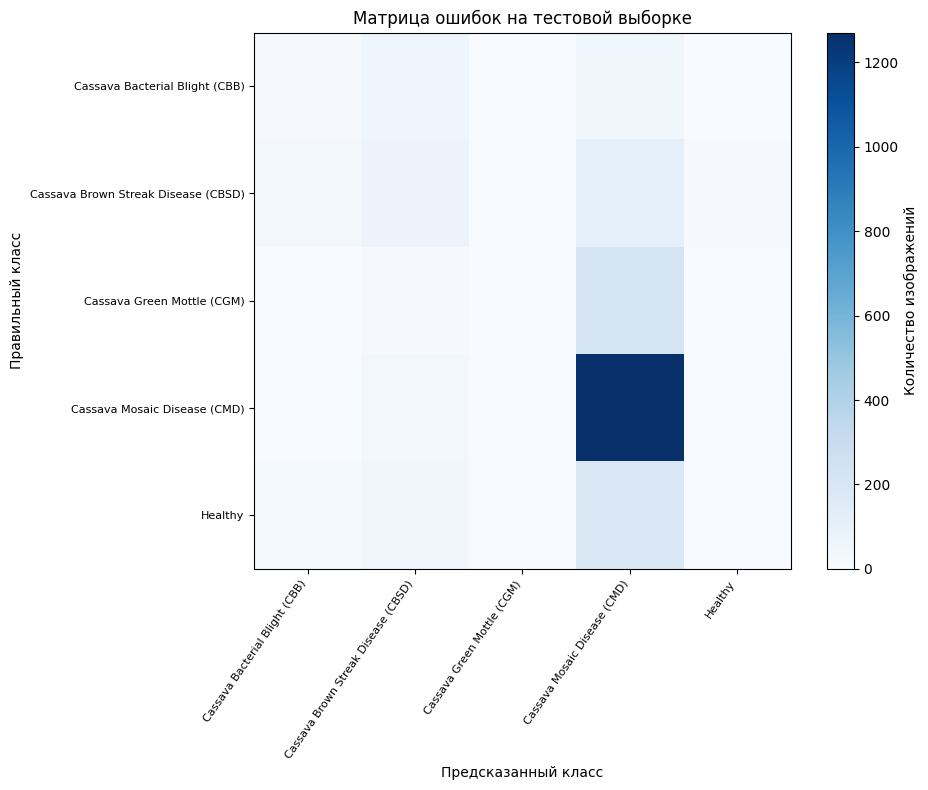

In [18]:
test_metrics = evaluate(model, test_loader)
print(
    f"Test loss: {test_metrics['loss']:.4f} | "
    f"Test accuracy: {test_metrics['accuracy']:.2%}"
)

confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
model.eval()
with torch.no_grad():
    for batch in test_loader:
        x = batch["image"].to(device)
        y = batch["label"].cpu()
        prediction = model(x).argmax(dim=-1).cpu()
        confusion += torch.bincount(y * NUM_CLASSES + prediction,
                                    minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

class_names = [
    label_names[str(i)]
    for i in range(NUM_CLASSES)
]
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), labels=class_names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES), labels=class_names, fontsize=8)
ax.set(
    xlabel="Предсказанный класс",
    ylabel="Правильный класс",
    title="Матрица ошибок на тестовой выборке",
)
plt.colorbar(im, ax=ax, label="Количество изображений")
plt.tight_layout()
plt.show()